Load results manually (clean)

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

files_list = ["BiLSTM-CRF.json", "BioLinkBERT.json", "PubMedBERT.json", "Mistral-7B.json"]

data = []

for file in files_list:
    with open(file, "r") as f:
        data.append(json.load(f))

df = pd.DataFrame(data)

df

,model,precision,recall,f1_score,accuracy,Chemical_precision,Chemical_recall,Chemical_f1,Disease_precision,Disease_recall,Disease_f1,Chemical_support,Disease_support
0,BiLSTM-CRF,0.635692,0.579361,0.606221,0.949973,0.694517,0.593088,0.639808,0.583236,0.565463,0.574212,NaN,NaN
1,BioLinkBERT,0.817100,0.808784,0.812921,0.977396,0.877888,0.863636,0.870704,0.758253,0.755037,0.756642,NaN,NaN
2,PubMedBERT,0.824759,0.824317,0.824538,0.977922,0.904494,0.871212,0.887541,0.752049,0.778367,0.764982,NaN,NaN
3,Mistral-7B,0.805195,0.358382,0.496000,0.951263,0.794872,0.468278,0.589354,0.823009,0.257618,0.392405,331.0,361.0


Global comparison table

In [2]:
# Sort by f1_score so all our plots are nicely ordered from best to worst
df = df.sort_values(by="f1_score", ascending=False)
df

,model,precision,recall,f1_score,accuracy,Chemical_precision,Chemical_recall,Chemical_f1,Disease_precision,Disease_recall,Disease_f1,Chemical_support,Disease_support
2,PubMedBERT,0.824759,0.824317,0.824538,0.977922,0.904494,0.871212,0.887541,0.752049,0.778367,0.764982,NaN,NaN
1,BioLinkBERT,0.817100,0.808784,0.812921,0.977396,0.877888,0.863636,0.870704,0.758253,0.755037,0.756642,NaN,NaN
0,BiLSTM-CRF,0.635692,0.579361,0.606221,0.949973,0.694517,0.593088,0.639808,0.583236,0.565463,0.574212,NaN,NaN
3,Mistral-7B,0.805195,0.358382,0.496000,0.951263,0.794872,0.468278,0.589354,0.823009,0.257618,0.392405,331.0,361.0


GLOBAL COMPARISON GRAPH (IMPORTANT)

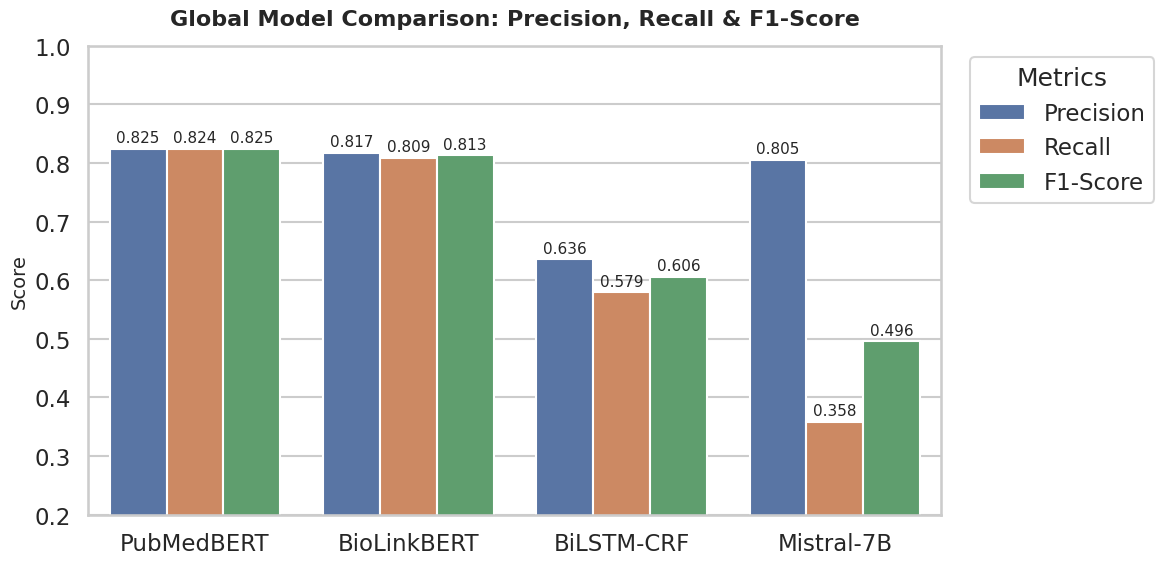

In [3]:
sns.set_theme(style="whitegrid", context="talk")
colors = ["#4C72B0", "#DD8452", "#55A868"]

df_global = df.melt(id_vars="model", value_vars=["precision", "recall", "f1_score"],
                    var_name="Metric", value_name="Score")
df_global['Metric'] = df_global['Metric'].str.replace('_', '-').str.title()

plt.figure(figsize=(12, 6))
ax1 = sns.barplot(data=df_global, x="model", y="Score", hue="Metric", palette=colors)
plt.title("Global Model Comparison: Precision, Recall & F1-Score", fontsize=16, weight='bold', pad=15)
plt.ylim(0.2, 1.0) # Adjusted zoom to accommodate Mistral's lower recall scores
plt.ylabel("Score", fontsize=14)
plt.xlabel("", fontsize=14)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc='upper left')

# Add data labels
for p in ax1.patches:
    ax1.annotate(format(p.get_height(), '.3f'),
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha = 'center', va = 'center', xytext = (0, 8),
                 textcoords = 'offset points', fontsize=11)

plt.tight_layout()
plt.show()

PER-ENTITY COMPARISON GRAPH (VERY IMPORTANT)

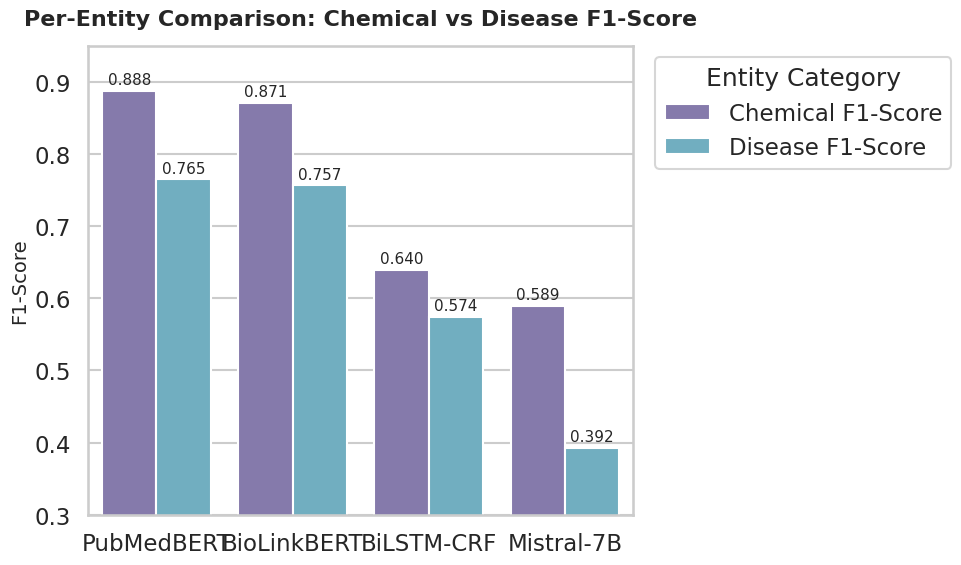

In [4]:
df_entity = df.melt(id_vars="model", value_vars=["Chemical_f1", "Disease_f1"],
                    var_name="Entity", value_name="F1_Score")
df_entity['Entity'] = df_entity['Entity'].str.replace('_f1', ' F1-Score')

plt.figure(figsize=(10, 6))
ax2 = sns.barplot(data=df_entity, x="model", y="F1_Score", hue="Entity", palette=["#8172B3", "#64B5CD"])
plt.title("Per-Entity Comparison: Chemical vs Disease F1-Score", fontsize=16, weight='bold', pad=15)
plt.ylim(0.3, 0.95) # Adjusted zoom to fit the new model
plt.ylabel("F1-Score", fontsize=14)
plt.xlabel("", fontsize=14)
plt.legend(title="Entity Category", bbox_to_anchor=(1.02, 1), loc='upper left')

# Add data labels
for p in ax2.patches:
    ax2.annotate(format(p.get_height(), '.3f'),
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha = 'center', va = 'center', xytext = (0, 8),
                 textcoords = 'offset points', fontsize=11)

plt.tight_layout()
plt.show()

ACCURACY COMPARISON

/tmp/ipykernel_14728/1388892150.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(data=df, x="model", y="accuracy", palette="magma")


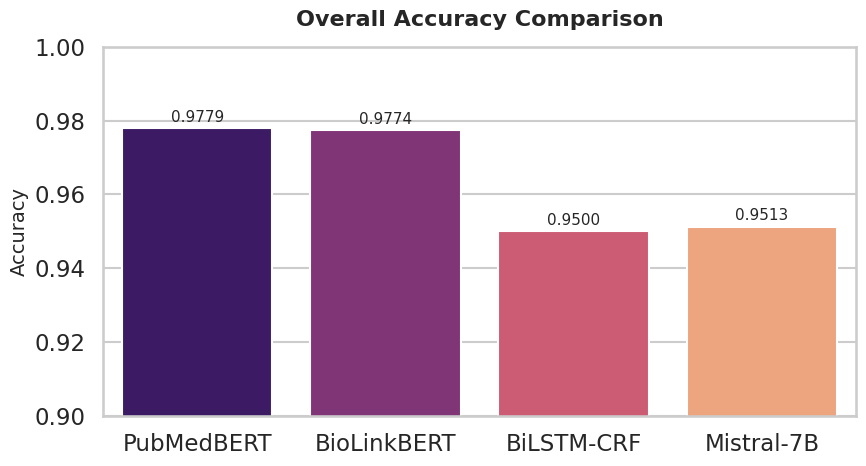

In [5]:
plt.figure(figsize=(9, 5))
ax3 = sns.barplot(data=df, x="model", y="accuracy", palette="magma")
plt.title("Overall Accuracy Comparison", fontsize=16, weight='bold', pad=15)
plt.ylim(0.9, 1.0) # Accuracies are still high for all models, keeping a tight zoom
plt.ylabel("Accuracy", fontsize=14)
plt.xlabel("", fontsize=14)

# Add data labels
for p in ax3.patches:
    ax3.annotate(format(p.get_height(), '.4f'),
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha = 'center', va = 'center', xytext = (0, 8),
                 textcoords = 'offset points', fontsize=11)

plt.tight_layout()
plt.show()

BEST MODEL

In [6]:
best = df.loc[df["f1_score"].idxmax()]
print("🏆 Best Model:", best["model"])

🏆 Best Model: PubMedBERT
